# AutoMetrics: Comparing Original Price and MSRP
This notebook adds a focused comparison of the two price measures. General inspection and feature relationships belong in `01_dataset_exploration.ipynb`. Brand-price rankings and SUV/sedan comparisons belong in the teammate's `02_brand_price_comparison.ipynb`. We do not repeat brand rankings here. This notebook also includes supplementary MSRP plots by body type, performance, and vehicle age; Notebook 01 covers original-price relationships.

We keep original price as the primary measure for the project and use MSRP as a secondary comparison. Currency and the source definitions remain unverified. Differences here describe the file, not proven dealer markups or transaction discounts.

## 1. Load the cleaned data
The workbook is read only. Missing values are not filled. Run from the project root or the notebooks folder.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
try:
    df = pd.read_excel("../data/processed/cars_dataset_cleaned.xlsx")
except FileNotFoundError:
    df = pd.read_excel("data/processed/cars_dataset_cleaned.xlsx")
print("Dataset shape:", df.shape)

Dataset shape: (100000, 26)


## 2. Check price availability
Show how many prices are available before comparing them. A row with one missing price cannot be used to calculate the difference between the two.

In [2]:
prices = df[["original_price", "msrp"]]
availability = pd.DataFrame({"Available": prices.count(), "Missing": prices.isna().sum(),
                             "Missing percent": prices.isna().mean() * 100})
availability

,Available,Missing,Missing percent
original_price,99000,1000,1.0
msrp,98000,2000,2.0


In [3]:
pd.crosstab(df["original_price"].isna(), df["msrp"].isna(),
            rownames=["Original price missing"], colnames=["MSRP missing"])

MSRP missing,False,True
Original price missing,,
False,97022,1978
True,978,22


## 3. Compare paired prices
Make a temporary table with both prices present. This does not remove rows from the dataset. A positive difference means MSRP is higher. Percentages are calculated only where original price is positive.

In [4]:
paired_prices = prices.dropna().copy()
paired_prices["difference"] = paired_prices["msrp"] - paired_prices["original_price"]
positive = paired_prices["original_price"] > 0
paired_prices["percentage_difference"] = (
    paired_prices.loc[positive, "difference"] /
    paired_prices.loc[positive, "original_price"] * 100
)
print("Paired records:", len(paired_prices))
print("Records not used in paired comparison:", len(df) - len(paired_prices))
print("Nonpositive original prices excluded from percentages:", (~positive).sum())
paired_prices.describe().round(3)

Paired records: 97022
Records not used in paired comparison: 2978
Nonpositive original prices excluded from percentages: 0


,original_price,msrp,difference,percentage_difference
count,97022.000,97022.000,97022.000,97022.000
mean,40383.233,41393.861,1010.628,2.501
std,22551.476,23128.133,875.547,1.441
min,12076.300,12094.060,0.000,0.000
25%,26715.465,27369.835,412.403,1.249
50%,34177.535,35055.175,828.025,2.500
75%,44913.417,46051.905,1331.702,3.748
max,198709.380,208363.820,9654.440,5.000


## 4. View the percentage differences
This histogram shows whether the gap between the two price measures is consistent across records.

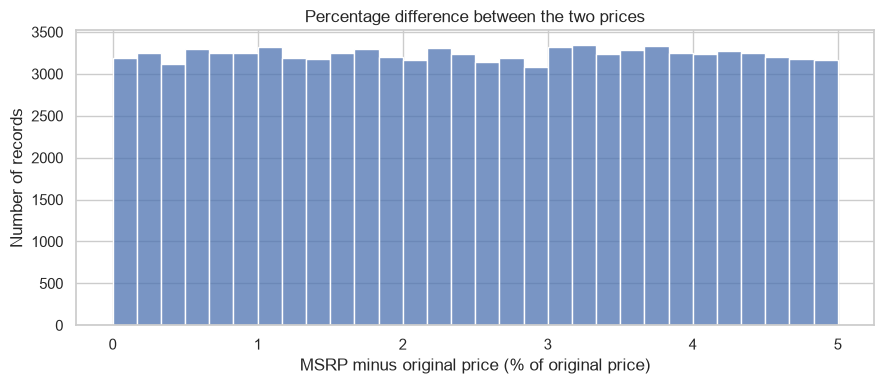

In [5]:
plt.figure(figsize=(9, 4))
sns.histplot(data=paired_prices, x="percentage_difference", bins=30)
plt.xlabel("MSRP minus original price (% of original price)")
plt.ylabel("Number of records")
plt.title("Percentage difference between the two prices")
plt.tight_layout()
plt.show()

## 5. Check how closely the prices move together
Correlation near 1 means the two prices tend to rise together. It does not tell us how either column was constructed.

In [6]:
print("MSRP below original price:", (paired_prices["difference"] < 0).sum())
print("Equal prices:", (paired_prices["difference"] == 0).sum())
paired_prices[["original_price", "msrp"]].corr().round(6)

MSRP below original price: 0
Equal prices: 1


,original_price,msrp
original_price,1.000000,0.999584
msrp,0.999584,1.000000


## 6. Visualize the absolute price gap
The percentage gap and the gap in dataset units answer different questions. A small percentage can still mean a large difference for an expensive vehicle. This histogram uses all paired records.

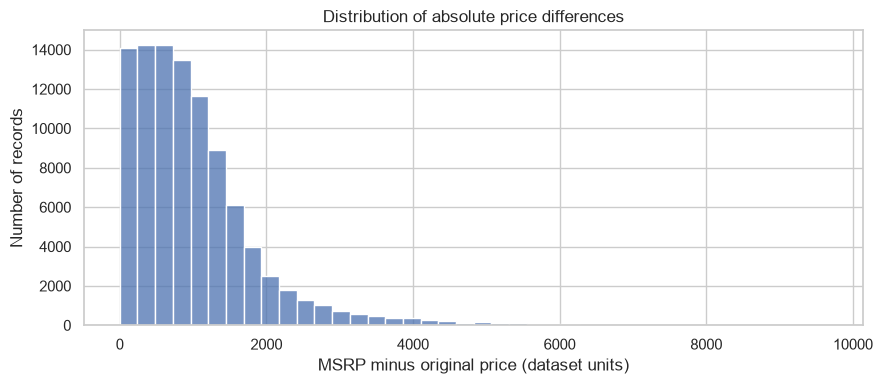

In [7]:
plt.figure(figsize=(9, 4))
sns.histplot(data=paired_prices, x="difference", bins=40)
plt.xlabel("MSRP minus original price (dataset units)")
plt.ylabel("Number of records")
plt.title("Distribution of absolute price differences")
plt.tight_layout()
plt.show()

## 7. Plot original price against MSRP
Each point is one record. The dashed line shows where the two prices would be equal. Points above the line have a higher MSRP. We use a fixed sample of up to 8,000 paired records to keep the plot readable; all numerical summaries use every available pair.

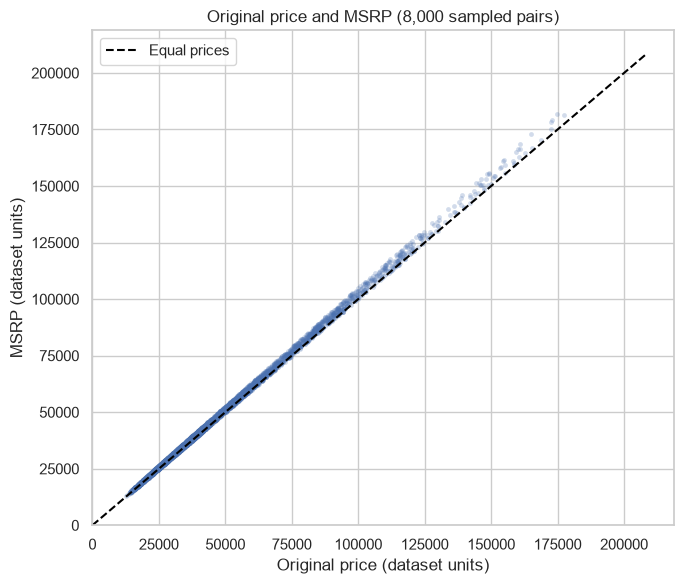

In [8]:
sample_size = min(8000, len(paired_prices))
plot_prices = paired_prices.sample(n=sample_size, random_state=42)
plt.figure(figsize=(7, 6))
sns.scatterplot(data=plot_prices, x="original_price", y="msrp",
                alpha=0.25, s=12, linewidth=0)
upper_price = paired_prices[["original_price", "msrp"]].max().max()
plt.plot([0, upper_price], [0, upper_price], linestyle="--", color="black", label="Equal prices")
plt.xlim(0, upper_price * 1.05)
plt.ylim(0, upper_price * 1.05)
plt.xlabel("Original price (dataset units)")
plt.ylabel("MSRP (dataset units)")
plt.title(f"Original price and MSRP ({sample_size:,} sampled pairs)")
plt.legend()
plt.tight_layout()
plt.show()

The points sit close to the equality line, consistent with the correlation of 0.999584 and percentage gaps of approximately 0–5%. This pattern alone cannot establish whether one column was generated from the other.

## 8. Does the choice of price measure change the relationships?
Notebook 01 explores relationships with original price. Here we ask a narrower question: do those relationships look different if we use MSRP instead?

Compare both price measures on exactly the same complete records for four characteristics. This avoids mixing price definitions with differences in which rows are available. Brand rankings remain in Notebook 02; the following section adds MSRP-specific body-type, performance, and age plots. Correlation measures association, not causation.

In [9]:
features = ["performance_score", "safety_feature_count", "power_to_weight_ratio", "vehicle_age"]
comparison_columns = ["original_price", "msrp"] + features
comparison = df[comparison_columns].dropna()
print("Records used for both price measures:", len(comparison))
price_correlations = comparison.corr().loc[features, ["original_price", "msrp"]]
price_correlations.round(4)

Records used for both price measures: 97022


,original_price,msrp
performance_score,0.3582,0.3581
safety_feature_count,0.4882,0.4879
power_to_weight_ratio,0.6385,0.6381
vehicle_age,-0.0046,-0.0046


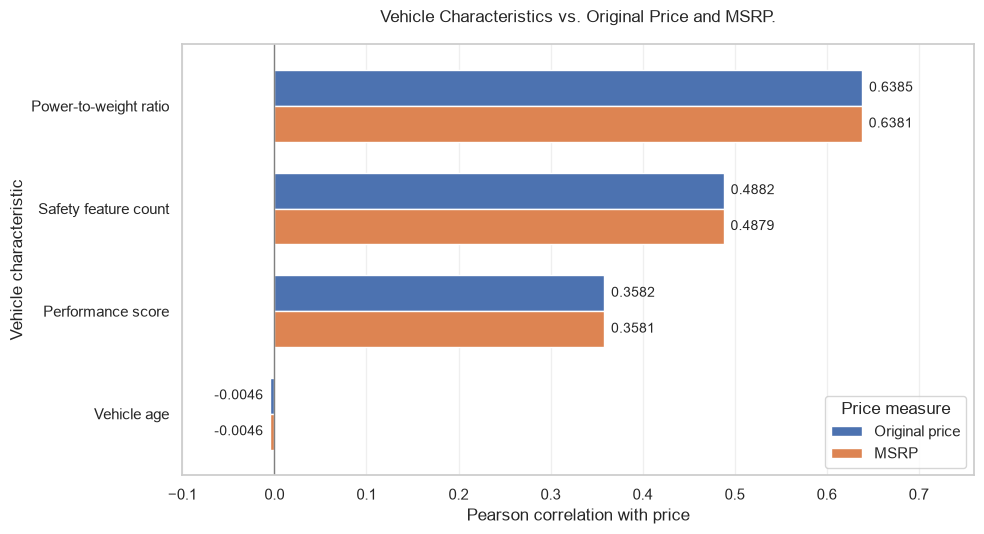

In [10]:
# Sort a plotting copy by absolute original-price correlation (strongest first).
plot_correlations = price_correlations.loc[
    price_correlations["original_price"].abs().sort_values(ascending=False).index
].rename(index={
    "power_to_weight_ratio": "Power-to-weight ratio",
    "safety_feature_count": "Safety feature count",
    "performance_score": "Performance score",
    "vehicle_age": "Vehicle age"
}, columns={"original_price": "Original price", "msrp": "MSRP"})

ax = plot_correlations.plot(
    kind="barh", figsize=(10, 5.5), width=0.7,
    color=["#4C72B0", "#DD8452"]
)
ax.invert_yaxis()
# Leave space for labels while keeping small negative age correlations visible.
ax.set_xlim(-0.10, 0.76)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.4f", padding=5, fontsize=10)
ax.axvline(0, color="gray", linewidth=1)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.3)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Pearson correlation with price")
ax.set_ylabel("Vehicle characteristic")
ax.set_title("Vehicle Characteristics vs. Original Price and MSRP.", pad=16)
ax.legend(title="Price measure", loc="lower right", frameon=True)
plt.tight_layout()
plt.show()

Similar bars mean that the overall linear relationships are not very sensitive to the price measure in this dataset. This is expected when the prices are so closely related. It is not independent confirmation of a causal explanation. Safety-feature count is not a safety rating, and power-to-weight ratio is not horsepower.

## 9. Supplementary MSRP visualizations

These three plots reproduce the MSRP analyses from the original visualization script. They complement the original-price charts in Notebook 01. Each calculation uses available MSRP values from the shared cleaned dataset, even when original price is missing. No missing prices are filled and the dataset is not changed. Prices are in dataset units because the currency is unverified.

### Median MSRP by Body Type
Compare typical MSRP across body types using medians, which are less affected by very expensive cars. Counts show the number of available prices in each category.

,count,median
body_type,,
Hatchback,14333,23548.39
Crossover,3300,25732.40
Sedan,22223,29240.42
Pickup,8384,34037.99
Minivan,3181,36021.39
SUV,35768,38444.07
Van,1260,40992.82
Convertible,850,48204.06
Coupe,8701,52295.56


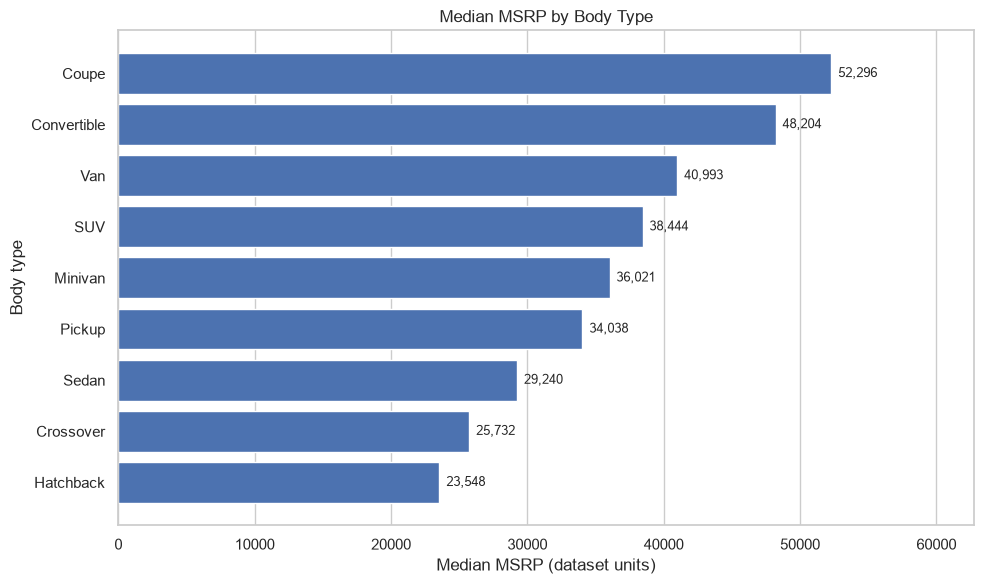

In [11]:
msrp_by_body = df.groupby("body_type")["msrp"].agg(["count", "median"])
msrp_by_body = msrp_by_body.sort_values("median")
display(msrp_by_body.round(2))

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(msrp_by_body.index, msrp_by_body["median"], color="#4C72B0")
labels = [f"{value:,.0f}" for value in msrp_by_body["median"]]
ax.bar_label(bars, labels=labels, padding=5, fontsize=9)
ax.set_xlim(0, msrp_by_body["median"].max() * 1.20)
ax.ticklabel_format(style="plain", axis="x")
ax.set_title("Median MSRP by Body Type")
ax.set_xlabel("Median MSRP (dataset units)")
ax.set_ylabel("Body type")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Body-type findings:** Coupes have the highest median MSRP (52,295.56), followed by convertibles (48,204.07). Hatchbacks have the lowest median (23,548.39). SUVs have a median of 38,444.07 and sedans 29,240.42. These groups contain different brands and models, so the chart does not isolate the effect of body type.

### MSRP vs. Performance Score
Each point represents a vehicle. A fixed random sample of up to 8,000 available records keeps the plot readable and reproducible. The correlation uses all complete MSRP/performance pairs, not just the plotted sample. We use a single color rather than the unclear `brand_premium_index` variable.

Available MSRP/performance pairs: 98000
Correlation: 0.358


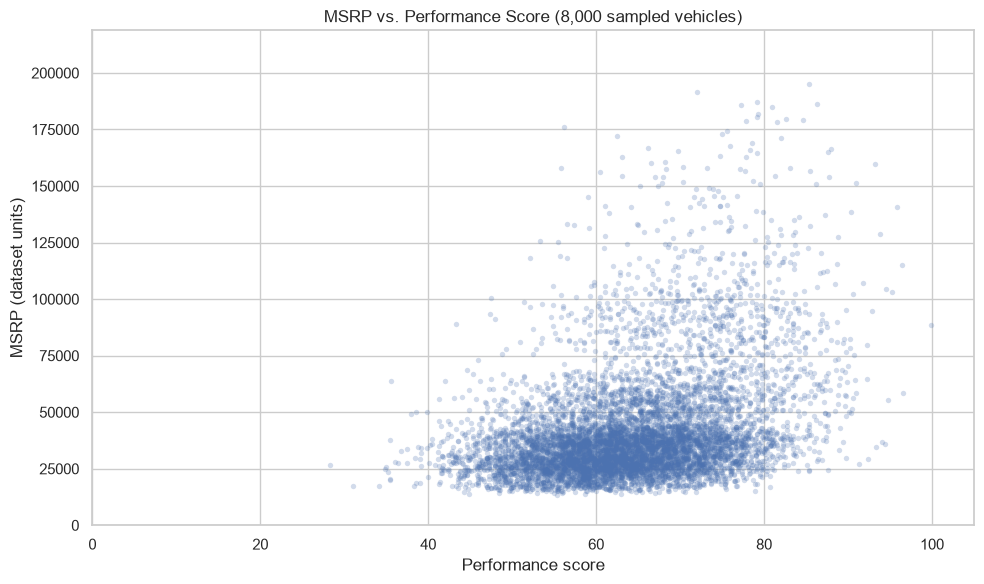

In [12]:
# This temporary selection does not change df or the saved dataset.
msrp_performance = df[["performance_score", "msrp"]].dropna()
performance_sample = msrp_performance.sample(
    n=min(8000, len(msrp_performance)), random_state=42
)
print("Available MSRP/performance pairs:", len(msrp_performance))
print("Correlation:", round(msrp_performance["msrp"].corr(
    msrp_performance["performance_score"]), 3))

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=performance_sample, x="performance_score", y="msrp",
                color="#4C72B0", alpha=0.25, s=15, linewidth=0, ax=ax)
ax.set_xlim(0, msrp_performance["performance_score"].max() * 1.05)
ax.set_ylim(0, msrp_performance["msrp"].max() * 1.05)
ax.ticklabel_format(style="plain", axis="y")
ax.set_title(f"MSRP vs. Performance Score ({len(performance_sample):,} sampled vehicles)")
ax.set_xlabel("Performance score")
ax.set_ylabel("MSRP (dataset units)")
plt.tight_layout()
plt.show()

**Performance findings:** Across 98,000 complete pairs, the correlation is approximately 0.358. Higher performance scores tend to accompany higher MSRP, but prices vary widely at similar scores. Performance alone does not explain the price differences, and correlation does not establish causation.

### Median MSRP Across Vehicle Age (0–15 Years)
Calculate the median separately for each age from 0 through 15, using all available MSRP values in that range. The y-axis starts at zero to keep small differences in perspective. This compares different vehicles at different ages, not the same vehicles followed over time.

,count,median
vehicle_age,,
0,9712,35165.34
1,11175,35076.09
2,9644,35054.26
3,8445,34716.56
4,8640,35478.38
5,7300,35297.78
6,7363,34706.35
7,6069,35184.11
8,6112,34815.46


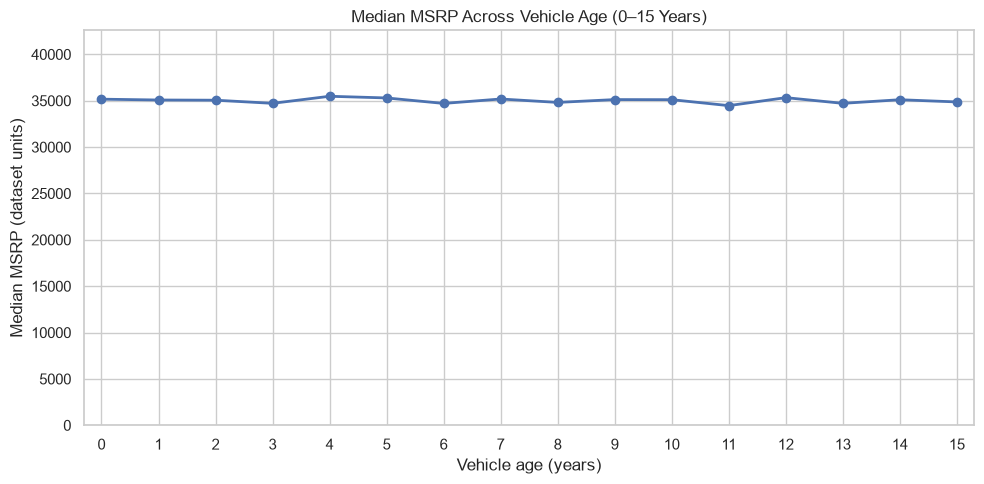

In [13]:
age_selection = df[df["vehicle_age"].between(0, 15)]
msrp_by_age = age_selection.groupby("vehicle_age")["msrp"].agg(["count", "median"])
msrp_by_age = msrp_by_age.sort_index()
display(msrp_by_age.round(2))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(msrp_by_age.index, msrp_by_age["median"],
        marker="o", color="#4C72B0", linewidth=2)
ax.set_xlim(-0.3, 15.3)
ax.set_xticks(range(16))
ax.set_ylim(0, msrp_by_age["median"].max() * 1.20)
ax.ticklabel_format(style="plain", axis="y")
ax.set_title("Median MSRP Across Vehicle Age (0–15 Years)")
ax.set_xlabel("Vehicle age (years)")
ax.set_ylabel("Median MSRP (dataset units)")
plt.tight_layout()
plt.show()

**Vehicle-age findings:** Median MSRP ranges from 34,468.00 at age 11 to 35,478.38 at age 4. It stays near 35,000 across the displayed ages, without a clear downward pattern. The number of available prices varies from 1,264 at age 15 to 11,175 at age 1. This chart cannot establish depreciation: the meaning of the MSRP field is unverified, and each age group contains different vehicles.

**Supplement summary:** MSRP differs noticeably by body type and has a positive association with performance, while median MSRP varies little across age groups. These patterns are descriptive and closely related to the original-price findings. Brand MSRP rankings and the manually defined luxury grouping are shown only in Notebook 02.

## 10. Conclusions and handoff

- Both prices are available for **97,022 records**; **2,978** are excluded only from the paired comparison. There are **22 records** missing both prices.
- MSRP is never lower than original price among paired records; one pair is equal.
- The average difference is **1,010.63 dataset units** and the median difference is **828.03**.
- Percentage differences range from **0% to approximately 5%**, averaging **2.501%**.
- Their correlation is **0.999584**. The two columns contain very similar information; this does not verify their origin or meaning.

The price-gap comparisons describe paired observations only; the supplementary MSRP plots use all available MSRP values for each characteristic. They do not establish whether missingness is random, or whether either price was calculated from the other. Avoid treating two closely related price columns as independent explanations of vehicle cost.

**Team consistency note:** Notebook 02 now incorporates Dachi's corrected explanations and statistics from commit `ae90d32`, together with the supplementary MSRP-by-brand chart. All three notebooks use the same cleaned workbook and preserve missing prices. Original-price summaries use 99,000 available values, MSRP summaries use 98,000, and paired comparisons use 97,022. Different sample counts reflect which values are available, not different cleaning policies.

The useful price-comparison calculations and visualizations now live in this notebook, so separate Python analysis scripts are not needed. General missingness and original-price body-type, age, and performance analyses remain in Notebook 01. Brand rankings, including the supplementary MSRP ranking, belong in Notebook 02. Section 9 here adds the three MSRP-specific plots. The existing exported PNGs are preserved as earlier supporting figures; this notebook displays its own graphs inline. The brand premium index is not used as a price explanation because its definition is unknown.

**Price-measure check:** On the same 97,022 records, correlations are nearly identical: performance 0.3582 versus 0.3581, safety-feature count 0.4882 versus 0.4879, power-to-weight ratio 0.6385 versus 0.6381, and age −0.0046 for both. Using MSRP instead of original price makes little difference to these overall linear relationships.